In [109]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import plotnine
from plotnine import *

In [110]:
url = "https://tastesbetterfromscratch.com/meal-plan-209/"
headers ={ "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)" }

req = requests.Session()

response = req.get(url, headers=headers)
soup = BeautifulSoup(response.content, "html.parser")

**Pulling the day, recipe name, link to it, and price**

In [111]:
days_week = ["Monday", "Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

In [112]:
rows = []

meal_p_tags = soup.find_all("p", attrs={"class":"has-text-align-left"})

for p_tag in meal_p_tags:

    day_strong = p_tag.find("strong")
    day = day_strong.get_text(strip=True).rstrip(":: - --").strip()

    if day not in days_week:
        continue

    recipe_name = p_tag.find("a")
    name = recipe_name.get_text(strip=True)
    link = recipe_name["href"] if recipe_name and recipe_name.has_attr("href") else ""

    just_price = p_tag.get_text(" ", strip=True)
    price_tag = re.search(r'\$\d+', just_price)
    price = price_tag.group(0) if price_tag else ""

    if day in days_week and name:
        rows.append({
            "Day of the Week": day,
            "Name of Recipe": name,
            "Link to Recipe": link,
            "Price of Recipe": price
        })

print(rows)

[{'Day of the Week': 'Monday', 'Name of Recipe': 'Peanut Noodles', 'Link to Recipe': 'https://tastesbetterfromscratch.com/peanut-noodles/', 'Price of Recipe': '$5'}, {'Day of the Week': 'Tuesday', 'Name of Recipe': 'Street Corn Chicken Bowl', 'Link to Recipe': 'https://tastesbetterfromscratch.com/street-corn-chicken-rice-bowls/', 'Price of Recipe': '$14'}, {'Day of the Week': 'Wednesday', 'Name of Recipe': 'BBQ Pulled Pork Sandwiches', 'Link to Recipe': 'https://tastesbetterfromscratch.com/bbq-pulled-pork-sandwiches-with-pineapple-mango-slaw/', 'Price of Recipe': '$25'}, {'Day of the Week': 'Thursday', 'Name of Recipe': 'Shrimp Alfredo', 'Link to Recipe': 'https://tastesbetterfromscratch.com/shrimp-alfredo/', 'Price of Recipe': '$10'}, {'Day of the Week': 'Friday', 'Name of Recipe': 'Chicken Caesar Wrap', 'Link to Recipe': 'https://tastesbetterfromscratch.com/chicken-caesar-wrap/', 'Price of Recipe': '$14'}]


**Putting the information is a DataFrame**

In [113]:
plan209 = pd.DataFrame(rows)
plan209

,Day of the Week,Name of Recipe,Link to Recipe,Price of Recipe
0,Monday,Peanut Noodles,https://tastesbetterfromscratch.com/peanut-noo...,$5
1,Tuesday,Street Corn Chicken Bowl,https://tastesbetterfromscratch.com/street-cor...,$14
2,Wednesday,BBQ Pulled Pork Sandwiches,https://tastesbetterfromscratch.com/bbq-pulled...,$25
3,Thursday,Shrimp Alfredo,https://tastesbetterfromscratch.com/shrimp-alf...,$10
4,Friday,Chicken Caesar Wrap,https://tastesbetterfromscratch.com/chicken-ca...,$14


**Checking to see the amount of results yielded on this serach prior to scraping for the first 100**

In [114]:
url = "https://tasty.p.rapidapi.com/recipes/list"

querystring = {"from":"0","size":"20","q":"Peanut Noodle"}

headers = {
    "X-RapidAPI-Key": 'b93baaa8e6mshfab5493aae9fadbp155792jsnff38e0d12616',
    "X-RapidAPI-Host": "tasty.p.rapidapi.com"
}

response = requests.get(url, headers=headers, params=querystring)

data = response.json()
len(data["results"])

20

**Now finding matching recipes in Tasty API for Monday: Peanut Noodle**

In [115]:
query = "Peanut Noodle"

def first_hundred_matches(size=20,matches=100):
  url = "https://tasty.p.rapidapi.com/recipes/list"

  querystring = {"from":"0","size":str(matches),"q": query}

  headers = {
      "X-RapidAPI-Key": 'b93baaa8e6mshfab5493aae9fadbp155792jsnff38e0d12616',
      "X-RapidAPI-Host": "tasty.p.rapidapi.com"
  }

  response = requests.get(url, headers=headers, params=querystring)
  similar_recipes = response.json()

  return similar_recipes.get("results", [])[:matches]

In [116]:
pnoodles_recipes = first_hundred_matches()
print(len(pnoodles_recipes))

24


In [117]:
pnoodles = pd.json_normalize(pnoodles_recipes)
pnoodles = pnoodles[['name', 'num_servings', 'total_time_minutes', 'video_url', 'user_ratings.score']]
pnoodles.head(24)

,name,num_servings,total_time_minutes,video_url,user_ratings.score
0,Sesame Peanut Noodles,4.0,25.0,https://vid.tasty.co/output/90034/hls24_152407...,0.926915
1,Peanut Noodle Pasta Salad,8.0,90.0,https://vid.tasty.co/output/51686/low_15050436...,0.958152
2,Pork Noodle Bowl,4.0,0.0,https://vid.tasty.co/output/141726/hls24_15656...,0.960894
3,Thai-Style Chicken And Prawn Fried Noodles (Pa...,4.0,25.0,https://vid.tasty.co/output/27753/low_14907233...,0.926230
4,One-Pot Pad Thai,4.0,35.0,https://vid.tasty.co/output/31989/low_14951250...,0.932827
5,Classic Pad Thai,4.0,55.0,https://vid.tasty.co/output/71654/hls24_151543...,0.909483
6,5-Ingredient Zucchini Noodles With Spicy Peanu...,2.0,15.0,https://vid.tasty.co/output/130560/hls24_15559...,0.800000
7,Pad Thai Spaghetti Squash,2.0,65.0,https://vid.tasty.co/output/55204/low_15072466...,0.924731
8,Lazy Girl 5 Minute Noodles,1.0,10.0,https://vid.tasty.co/output/231117/hls24_16444...,0.809859
9,Stir Fry Inspired By Migos,4.0,40.0,https://vid.tasty.co/output/79312/hls24_151873...,0.912088


**Here we will begin to create the function to get the weekly plan. However, we will first define 2 functions that the main function will utilize.**



In [118]:
def get_weekly_plan(plan_number):

  plan_number = int(plan_number)
  if plan_number not in range(100, 211):
      raise ValueError("week must be between 100 and 210")

  URL = f"https://tastesbetterfromscratch.com/meal-plan-{plan_number}/"
  HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
  response = requests.get(URL, headers=HEADERS)
  soup = BeautifulSoup(response.text, "html.parser")

  days_week = ["Monday", "Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

  meal_p_tags = soup.find_all("p", attrs={"class":"has-text-align-left"})

  rows = []

  for p_tag in meal_p_tags:

    day_strong = p_tag.find("strong")
    day = day_strong.get_text(strip=True).rstrip(":: - --").strip()

    if day not in days_week:
        continue

    recipe_name = p_tag.find("a")
    name = recipe_name.get_text(strip=True)
    link = recipe_name["href"] if recipe_name and recipe_name.has_attr("href") else ""

    just_price = p_tag.get_text(" ", strip=True)
    price_tag = re.search(r'\$\d+', just_price)
    price = price_tag.group(0) if price_tag else ""

    if day in days_week and name:
        rows.append({
            "Day of the Week": day,
            "Name of Recipe": name,
            "Link to Recipe": link,
            "Price of Recipe": price
        })

  meal_plans = pd.DataFrame(rows)
  return meal_plans

df = get_weekly_plan(210)
df.head()


,Day of the Week,Name of Recipe,Link to Recipe,Price of Recipe
0,Monday,Biscuit Chicken Pot Pie,https://tastesbetterfromscratch.com/biscuit-ch...,$11
1,Tuesday,Calzone,https://tastesbetterfromscratch.com/calzones/,$8
2,Wednesday,Quinoa Burger,https://tastesbetterfromscratch.com/quinoa-veg...,$15
3,Thursday,Short Rib Ragu,https://tastesbetterfromscratch.com/short-rib-...,$26
4,Friday,Cabbage Roll Soup,https://tastesbetterfromscratch.com/cabbage-ro...,$20


In [119]:
def match_recipe(recipe_name: str, size=20, matches=100):

    clean_name = re.sub(r"[^A-Za-z0-9\s]", " ", recipe_name)
    clean_name = re.sub(r"\s+", " ", clean_name).strip()

    url = "https://tasty.p.rapidapi.com/recipes/list"
    querystring = {"from": "0", "size": str(matches), "q": clean_name}

    headers = {
        "X-RapidAPI-Key": "b93baaa8e6mshfab5493aae9fadbp155792jsnff38e0d12616",
        "X-RapidAPI-Host": "tasty.p.rapidapi.com"
    }

    response = requests.get(url, headers=headers, params=querystring)
    match_data = response.json()

    desired_cols = [
        "name", "num_servings", "total_time_minutes", "video_url",
        "user_ratings.score",
        "nutrition.calories", "nutrition.carbohydrates", "nutrition.fat",
        "nutrition.fiber", "nutrition.protein", "nutrition.sugar"
    ]

    recipe_info = pd.json_normalize(match_data.get("results", []), sep=".")
    recipe_info = recipe_info.reindex(columns=desired_cols).dropna()

    nutrition_rename = {
        "num_servings": "Number of Servings", "total_time_minutes": "Total time (minutes)",
        "video_url":"Video URL",
        "user_ratings.score":"User Rating",
        "nutrition.calories":"Calories",
        "nutrition.carbohydrates":"Carbohydrates",
        "nutrition.fat":"Fat",
        "nutrition.fiber":"Fiber",
        "nutrition.protein":"Protein",
        "nutrition.sugar":"Sugar"
    }
    recipe_info.rename(columns=nutrition_rename, inplace=True)

    return recipe_info.head(size)


**Checking if the tasty function works**

In [120]:
calzone_recipes = match_recipe("calzone")
calzone_recipes

,name,Number of Servings,Total time (minutes),Video URL,User Rating,Calories,Carbohydrates,Fat,Fiber,Protein,Sugar
0,Classic Meat Lover’s Calzones,4.0,110.0,https://vid.tasty.co/output/118284/hls24_15440...,0.961214,698.0,60.0,35.0,2.0,32.0,2.0
1,Deep-Fried Mini Calzones (Panzarotti),14.0,120.0,https://vid.tasty.co/output/71967/hls24_151554...,0.938462,295.0,27.0,14.0,1.0,14.0,1.0
2,Meatball Parmesan Calzones,8.0,40.0,https://vid.tasty.co/output/22266/low_14855388...,0.941606,265.0,28.0,11.0,1.0,10.0,2.0
3,Sheet Pan Calzone,8.0,60.0,https://vid.tasty.co/output/102816/hls24_15323...,0.957317,487.0,54.0,21.0,2.0,19.0,3.0
4,Spinach And Cheese Mini Calzones,8.0,50.0,https://vid.tasty.co/output/22266/low_14855388...,0.921348,97.0,1.0,8.0,0.0,4.0,0.0
5,Chicken Bacon Ranch Mini Calzones,8.0,50.0,https://vid.tasty.co/output/22266/low_14855388...,0.873016,143.0,4.0,8.0,21.0,11.0,0.0
6,Hawaiian Mini Calzones,8.0,40.0,https://vid.tasty.co/output/22266/low_14855388...,0.846154,236.0,38.0,5.0,2.0,7.0,11.0


**By using the functions for get_weekply_plan and match_recipe, we can now get the weekly meal plan data. In this section, after getting a match we also want to pull infrmation of the nutrional content.**

In [122]:
def get_mealplan_data(plan_number, size=20, matches=100):
    plan_df = get_weekly_plan(plan_number)
    frames = []

    for name in plan_df["Name of Recipe"].values:
        matched = match_recipe(name, size=size, matches=matches)
        matched2 = matched.copy()
        matched2["Name of Recipe"] = name
        frames.append(matched2)

    if frames:
        matched_df = pd.concat(frames, ignore_index=True)

    else:
        matched_df = pd.DataFrame(columns=["Name of Recipe"])

    merged = pd.merge(plan_df, matched_df, on="Name of Recipe", how="left").dropna()

    return merged


**Check in**

In [123]:
df = get_mealplan_data(202)
df.head(20)

,Day of the Week,Name of Recipe,Link to Recipe,Price of Recipe,name,Number of Servings,Total time (minutes),Video URL,User Rating,Calories,Carbohydrates,Fat,Fiber,Protein,Sugar
1,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Taiwanese Beef Noodle Soup,6.0,210.0,https://vid.tasty.co/output/92228/hls24_152528...,0.982692,887.0,81.0,33.0,9.0,68.0,15.0
2,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Classic Lasagna Soup,4.0,35.0,https://vid.tasty.co/output/210027/hls24_16268...,0.954939,697.0,44.0,31.0,3.0,50.0,10.0
3,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Traditional Vietnamese Beef Pho,8.0,480.0,https://vid.tasty.co/output/91445/hls24_152478...,0.906114,539.0,59.0,20.0,3.0,27.0,3.0
4,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Homemade Alphabet Soup,6.0,45.0,https://vid.tasty.co/output/30740/low_14937617...,0.890000,310.0,13.0,18.0,2.0,22.0,4.0
5,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Vodka Sauce Lasagna Soup,4.0,50.0,https://vid.tasty.co/output/360629/hls24_17319...,0.911765,959.0,29.0,59.0,2.0,46.0,9.0
6,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Korean Cold Noodles (Mul Naengmyeon),4.0,90.0,https://vid.tasty.co/output/202355/hls24_16204...,0.687500,834.0,120.0,14.0,13.0,56.0,21.0
7,Wednesday,Stuffed Shells,https://tastesbetterfromscratch.com/lasagna-st...,$12,Meatball Stuffed Shell Pasta,4.0,50.0,https://vid.tasty.co/output/86491/hls24_152184...,0.956772,1500.0,113.0,72.0,7.0,99.0,17.0
8,Wednesday,Stuffed Shells,https://tastesbetterfromscratch.com/lasagna-st...,$12,Enchilada Stuffed Shells,12.0,70.0,https://vid.tasty.co/output/32017/low_14951249...,0.954819,142.0,4.0,9.0,0.0,9.0,2.0
9,Wednesday,Stuffed Shells,https://tastesbetterfromscratch.com/lasagna-st...,$12,Stuffed Shells,8.0,55.0,https://vid.tasty.co/output/209360/hls24_16262...,0.957500,348.0,11.0,23.0,1.0,23.0,4.0
10,Wednesday,Stuffed Shells,https://tastesbetterfromscratch.com/lasagna-st...,$12,Enchilada-inspired Stuffed Shells,5.0,40.0,https://vid.tasty.co/output/34570/low_14979974...,0.962825,708.0,74.0,23.0,4.0,42.0,6.0


In [124]:
df = df.reset_index(drop=True)

**Now we want to identify anything that has meat in it based on a common dictionary of proteins. This helps with any fuzzy matching, such that it identifies whether the recipe is vegetarian or not**

In [125]:
meats = ["chicken","pork","bacon","turkey","steak","lamb","ham","pepperoni","chorizo",
         "bison","grass-fed","salami","prosciutto","cod","beef","duck"]  # removed plain "meat"
fish = ["fish","shrimp","salmon","tuna","crab","lobster","anchovy"]
broth_sauce = ["chicken broth","beef broth","chicken stock","beef stock","bonito","dashi","fish sauce"]
vegetarian = ["veggie","meatless","plant based","vegetarian","vegan"]

veg_pattern  = r'(' + '|'.join(vegetarian) + r')'
meat_pattern = r'(' + '|'.join(meats + fish + broth_sauce) + r')'

df["Vegetarian"] = True
for i in range(len(df)):
    parts = []
    if "Name of Recipe" in df.columns and pd.notna(df.at[i, "Name of Recipe"]):
        parts.append(str(df.at[i, "Name of Recipe"]))
    if "name" in df.columns and pd.notna(df.at[i, "name"]):
        parts.append(str(df.at[i, "name"]))
    text = " ".join(parts)

    if re.search(veg_pattern, text, flags=re.IGNORECASE):
        df.at[i, "Vegetarian"] = True
    elif re.search(meat_pattern, text, flags=re.IGNORECASE):
        df.at[i, "Vegetarian"] = False
    else:
        df.at[i, "Vegetarian"] = True

In [126]:
veg_recipe = {True:"Yes",
              False:"No"}

df["Vegetarian"] = df["Vegetarian"].replace(veg_recipe).fillna("no tasty match")
df.head(20)

,Day of the Week,Name of Recipe,Link to Recipe,Price of Recipe,name,Number of Servings,Total time (minutes),Video URL,User Rating,Calories,Carbohydrates,Fat,Fiber,Protein,Sugar,Vegetarian
0,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Taiwanese Beef Noodle Soup,6.0,210.0,https://vid.tasty.co/output/92228/hls24_152528...,0.982692,887.0,81.0,33.0,9.0,68.0,15.0,No
1,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Classic Lasagna Soup,4.0,35.0,https://vid.tasty.co/output/210027/hls24_16268...,0.954939,697.0,44.0,31.0,3.0,50.0,10.0,No
2,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Traditional Vietnamese Beef Pho,8.0,480.0,https://vid.tasty.co/output/91445/hls24_152478...,0.906114,539.0,59.0,20.0,3.0,27.0,3.0,No
3,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Homemade Alphabet Soup,6.0,45.0,https://vid.tasty.co/output/30740/low_14937617...,0.890000,310.0,13.0,18.0,2.0,22.0,4.0,No
4,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Vodka Sauce Lasagna Soup,4.0,50.0,https://vid.tasty.co/output/360629/hls24_17319...,0.911765,959.0,29.0,59.0,2.0,46.0,9.0,No
5,Tuesday,Beef Noodle Soup,https://tastesbetterfromscratch.com/beef-noodl...,$29,Korean Cold Noodles (Mul Naengmyeon),4.0,90.0,https://vid.tasty.co/output/202355/hls24_16204...,0.687500,834.0,120.0,14.0,13.0,56.0,21.0,No
6,Wednesday,Stuffed Shells,https://tastesbetterfromscratch.com/lasagna-st...,$12,Meatball Stuffed Shell Pasta,4.0,50.0,https://vid.tasty.co/output/86491/hls24_152184...,0.956772,1500.0,113.0,72.0,7.0,99.0,17.0,Yes
7,Wednesday,Stuffed Shells,https://tastesbetterfromscratch.com/lasagna-st...,$12,Enchilada Stuffed Shells,12.0,70.0,https://vid.tasty.co/output/32017/low_14951249...,0.954819,142.0,4.0,9.0,0.0,9.0,2.0,Yes
8,Wednesday,Stuffed Shells,https://tastesbetterfromscratch.com/lasagna-st...,$12,Stuffed Shells,8.0,55.0,https://vid.tasty.co/output/209360/hls24_16262...,0.957500,348.0,11.0,23.0,1.0,23.0,4.0,Yes
9,Wednesday,Stuffed Shells,https://tastesbetterfromscratch.com/lasagna-st...,$12,Enchilada-inspired Stuffed Shells,5.0,40.0,https://vid.tasty.co/output/34570/low_14979974...,0.962825,708.0,74.0,23.0,4.0,42.0,6.0,Yes


**Now we want to visualize this information. It will show the proportion by the macros and then a facet wrap to show the difference for those that are vegetarian and not.**

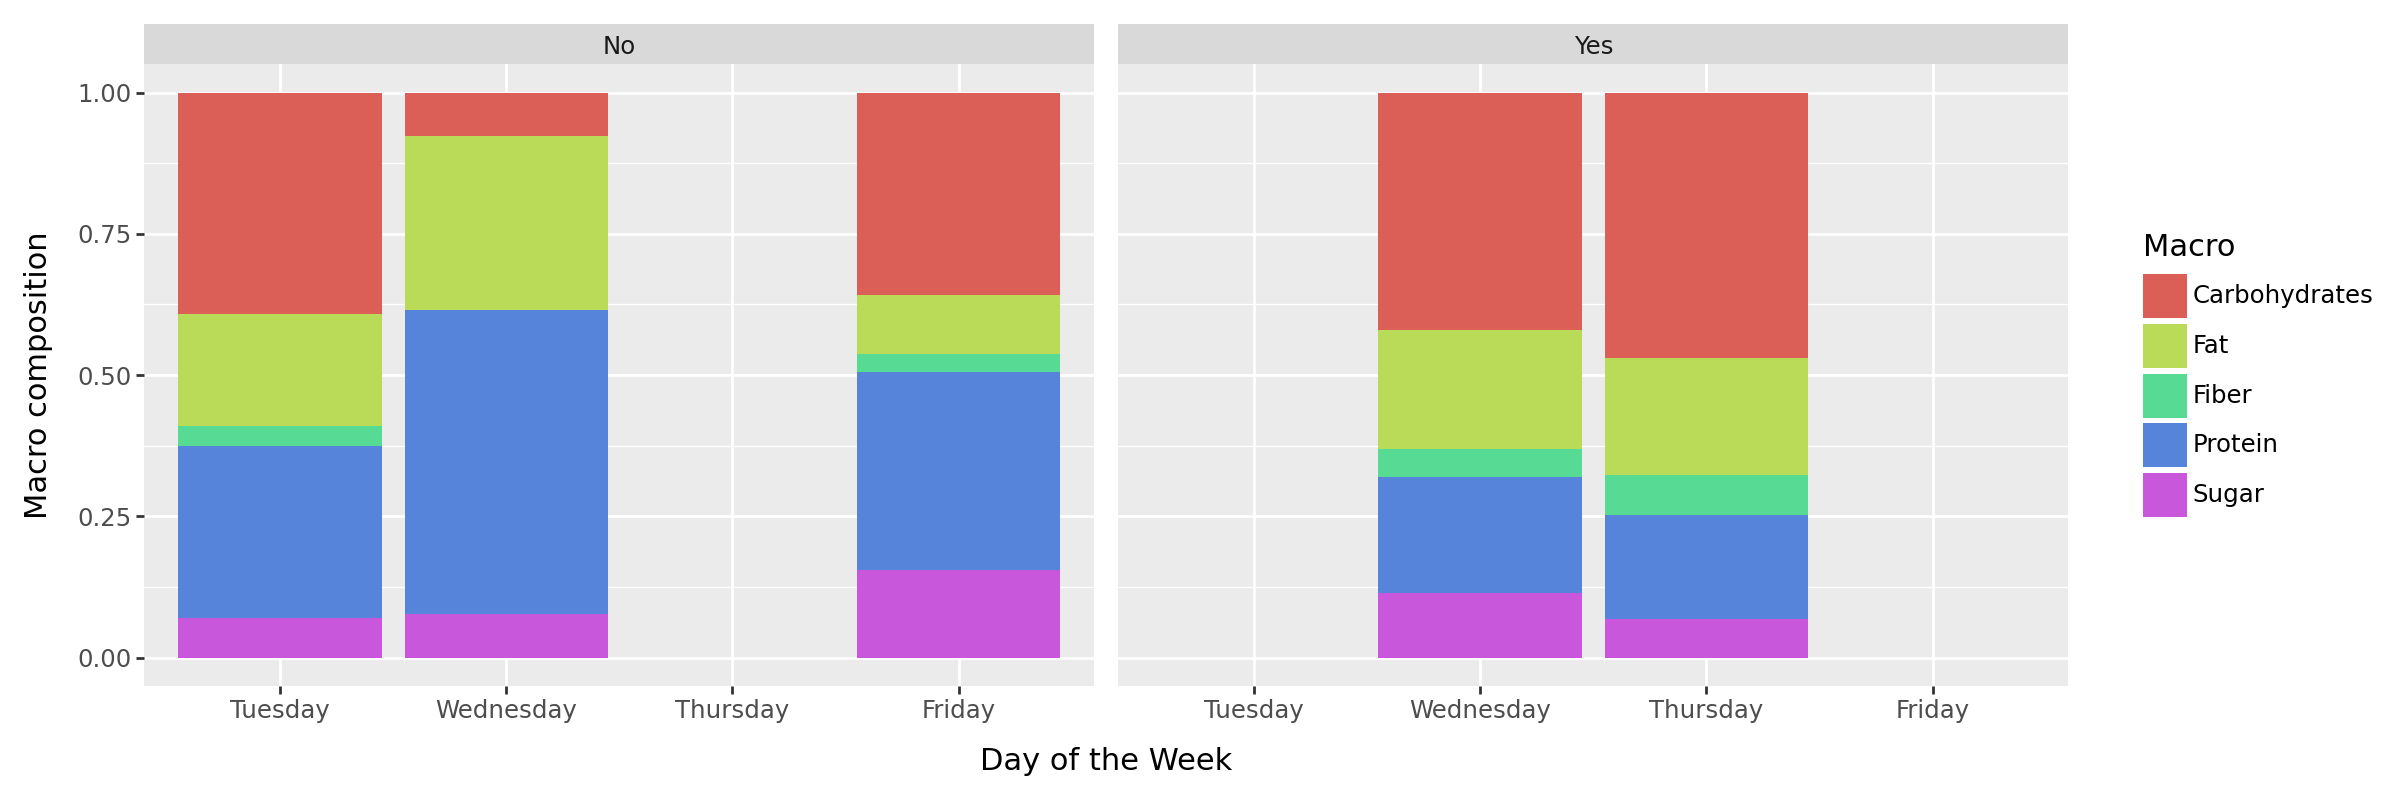

In [127]:
df_long = df.melt(
    id_vars=["Day of the Week","Vegetarian"],
    value_vars=["Carbohydrates","Fat","Fiber","Protein","Sugar"],
    var_name="Macro",
    value_name="Grams"
)

df_long["Grams"] = pd.to_numeric(df_long["Grams"], errors="coerce").fillna(0)
df_long["Vegetarian"] = df_long["Vegetarian"].dropna()
df_long["Day of the Week"] = pd.Categorical(
    df_long["Day of the Week"],
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"],
    ordered=True
)

(
    ggplot(df_long, aes(x="Day of the Week", y="Grams", fill="Macro"))
    + geom_bar(stat="identity", position="fill")
    + facet_wrap("~Vegetarian")
    + labs(x="Day of the Week", y="Macro composition", fill="Macro")
    + theme(figure_size=(12, 4))
)
